<a href="https://colab.research.google.com/github/AITrading1995/AITrading1995/blob/main/Volatility_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. ติดตั้ง Library ที่จำเป็นและดึงข้อมูลจาก yfinance

In [1]:
!pip install yfinance pandas numpy matplotlib

In [18]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ดึงข้อมูลหุ้นตัวอย่าง (เช่น SPY หรือ PTT.BK สำหรับหุ้นไทย)
ticker = 'GC=F'
start_date = '2026-01-01'
end_date = '2026-10-08'

raw_data = yf.download(ticker, start=start_date, end=end_date)
display(raw_data.head())

/tmp/ipykernel_1934/2996124311.py:11: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw_data = yf.download(ticker, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,GC=F,GC=F,GC=F,GC=F,GC=F
Date,,,,,
2026-01-02,4329.600098,4414.799805,4319.700195,4340.000000,154807
2026-01-05,4451.500000,4467.600098,4354.600098,4368.299805,211711
2026-01-06,4496.100098,4508.299805,4437.899902,4459.799805,176584
2026-01-07,4462.500000,4512.399902,4432.899902,4505.399902,202783
2026-01-08,4460.700195,4489.299805,4415.000000,4467.100098,208958


### 2. Data Pipeline & Feature Engineering

เราจะคำนวณ Daily Returns และสร้างฟีเจอร์สำหรับทำนาย Volatility เช่น:
- **Historical Volatility (Rolling Standard Deviation of Returns)**
- **Garman-Klass Volatility** (ใช้ข้อมูล Open, High, Low, Close เพื่อความแม่นยำขึ้น)
- **Rolling Return Averages & Standard Deviations**

In [19]:
def create_volatility_features(df, window=21):
    data = df.copy()

    # 1. คำนวณ Log Returns
    data['Log_Return'] = np.log(data['Close'] / data['Close'].shift(1))

    # 2. Realized Volatility (Rolling Std of Log Returns scaled to annual)
    # 252 คือจำนวนวันทำการใน 1 ปี
    data['Historical_Vol'] = data['Log_Return'].rolling(window=window).std() * np.sqrt(252)

    # 3. Parkinson Volatility (ใช้ High-Low)
    hl_ratio = np.log(data['High'] / data['Low']) ** 2
    data['Parkinson_Vol'] = np.sqrt((hl_ratio.rolling(window=window).sum() / (4 * window * np.log(2))) * 252)

    # 4. Lagged features (ใช้ค่า Volatility ย้อนหลังเป็นฟีเจอร์ทำนาย)
    data['Vol_Lag1'] = data['Historical_Vol'].shift(1)
    data['Vol_Lag5'] = data['Historical_Vol'].shift(5)

    # ลบแถวที่มีค่า NaN จากการทำ rolling/shift
    data = data.dropna()

    return data

# รัน pipeline เพื่อสร้างฟีเจอร์
featured_data = create_volatility_features(raw_data)
display(featured_data[['Close', 'Log_Return', 'Historical_Vol', 'Parkinson_Vol']].head())

Price,Close,Log_Return,Historical_Vol,Parkinson_Vol
Ticker,GC=F,,,
Date,,,,
2026-02-10,5031.000000,-0.009574,0.529042,0.539723
2026-02-11,5098.500000,0.013328,0.525111,0.538796
2026-02-12,4948.399902,-0.029882,0.538142,0.545835
2026-02-13,5046.299805,0.019591,0.540865,0.549420
2026-02-17,4905.899902,-0.028217,0.551995,0.556601


### 3. พล็อตข้อมูลเปรียบเทียบ Volatility

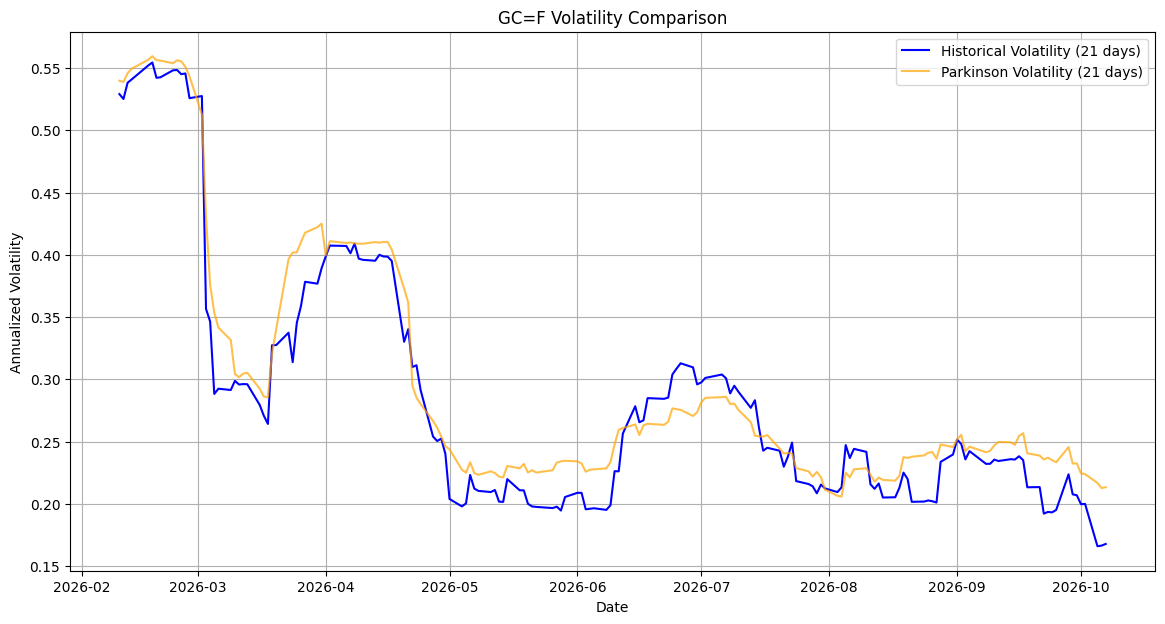

In [20]:
plt.figure(figsize=(14, 7))
plt.plot(featured_data['Historical_Vol'], label='Historical Volatility (21 days)', color='blue')
plt.plot(featured_data['Parkinson_Vol'], label='Parkinson Volatility (21 days)', color='orange', alpha=0.7)
plt.title(f'{ticker} Volatility Comparison')
plt.xlabel('Date')
plt.ylabel('Annualized Volatility')
plt.legend()
plt.grid(True)
plt.show()

### 4. การทำ Volatility Prediction (Machine Learning Baseline)

In [21]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. กำหนด Target (เช่น ทำนาย Volatility ของวันถัดไป)
featured_data['Target_Vol'] = featured_data['Historical_Vol'].shift(-1)

# ลบแถวสุดท้ายที่เป็น NaN จากการ shift Target
model_data = featured_data.dropna().copy()

# 2. กำหนด Features (X) และ Target (y)
features = ['Log_Return', 'Historical_Vol', 'Parkinson_Vol', 'Vol_Lag1', 'Vol_Lag5']
X = model_data[features]
y = model_data['Target_Vol']

# 3. แบ่งข้อมูล Train/Test (ตามลำดับเวลาเพื่อป้องกัน Data Leakage)
split_index = int(len(model_data) * 0.8)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

# 4. เทรนโมเดล Random Forest
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 5. ทำนายและวัดผล
predictions = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2) Score: {r2:.4f}")

Root Mean Squared Error (RMSE): 0.0157
R-squared (R2) Score: 0.5515


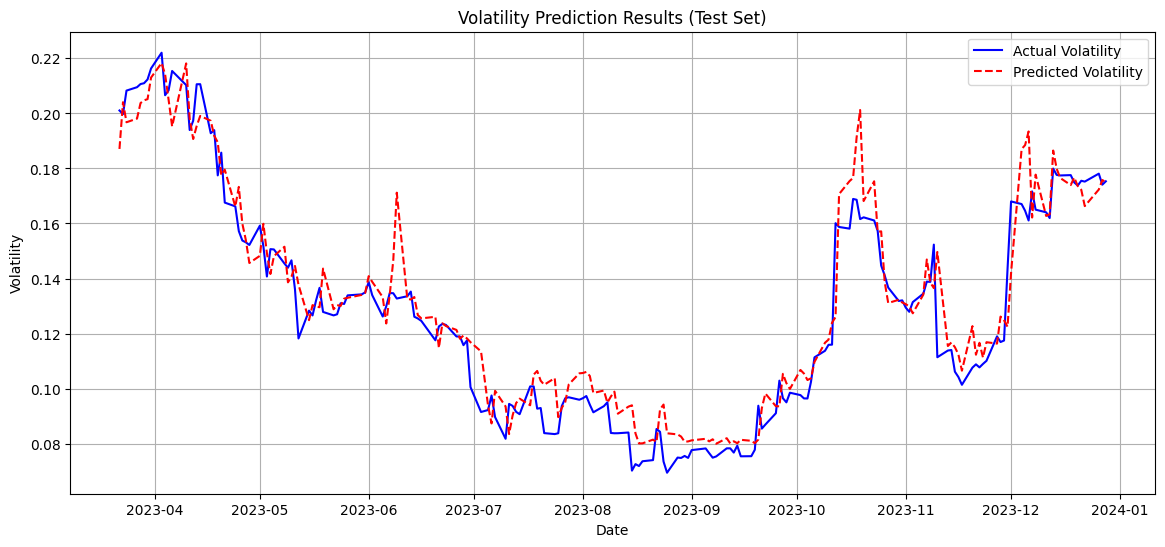

In [11]:
# พล็อตเปรียบเทียบค่าจริงกับการทำนายบน Test Set
plt.figure(figsize=(14, 6))
plt.plot(y_test.index, y_test.values, label='Actual Volatility', color='blue')
plt.plot(y_test.index, predictions, label='Predicted Volatility', color='red', linestyle='--')
plt.title('Volatility Prediction Results (Test Set)')
plt.xlabel('Date')
plt.ylabel('Volatility')
plt.legend()
plt.grid(True)
plt.show()

In [12]:
!pip install arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 32.6 MB/s eta 0:00:00


In [22]:
from arch import arch_model

# GARCH โมเดลจะทำงานโดยตรงกับค่า Returns
# เราจะใช้ Log_Return ของเซต Train ในการฟิตโมเดล
# คูณด้วย 100 เพื่อช่วยให้โมเดล GARCH หาค่าคอนเวอร์จได้เสถียรขึ้น (GARCH scale optimization)
train_returns = model_data['Log_Return'].iloc[:split_index] * 100
test_returns = model_data['Log_Return'].iloc[split_index:] * 100

# 1. กำหนดและฟิตโมเดล GARCH(1,1)
garch = arch_model(train_returns, vol='Garch', p=1, q=1, dist='normal')
garch_fitted = garch.fit(disp='off')

# 2. ทำการพยากรณ์ล่วงหน้า (Rolling Forecast แบบ Out-of-Sample)
garch_preds = []
# ใช้ข้อมูลสะสมในการพยากรณ์ความผันผวนทีละวันเพื่อเลียนแบบสถานการณ์จริง
for i in range(len(test_returns)):
    current_train = model_data['Log_Return'].iloc[:split_index + i] * 100
    temp_model = arch_model(current_train, vol='Garch', p=1, q=1, dist='normal')
    temp_fitted = temp_model.fit(disp='off')
    forecast = temp_fitted.forecast(horizon=1)
    # ดึงค่า Conditional Variance และแปลงกลับเป็น Standard Deviation รายปี (Annualized Volatility)
    pred_vol = np.sqrt(forecast.variance.iloc[-1].values[0]) / 100 * np.sqrt(252)
    garch_preds.append(pred_vol)

garch_preds = np.array(garch_preds)

# 3. คำนวณค่าทางสถิติเพื่อเปรียบเทียบ
garch_rmse = np.sqrt(mean_squared_error(y_test, garch_preds))
garch_r2 = r2_score(y_test, garch_preds)

print("=== ผลการเปรียบเทียบแบบจำลอง ===")
print(f"Random Forest - RMSE: {rmse:.4f} | R2: {r2:.4f}")
print(f"GARCH(1,1)    - RMSE: {garch_rmse:.4f} | R2: {garch_r2:.4f}")

=== ผลการเปรียบเทียบแบบจำลอง ===
Random Forest - RMSE: 0.0157 | R2: 0.5515
GARCH(1,1)    - RMSE: 0.0419 | R2: -2.2010


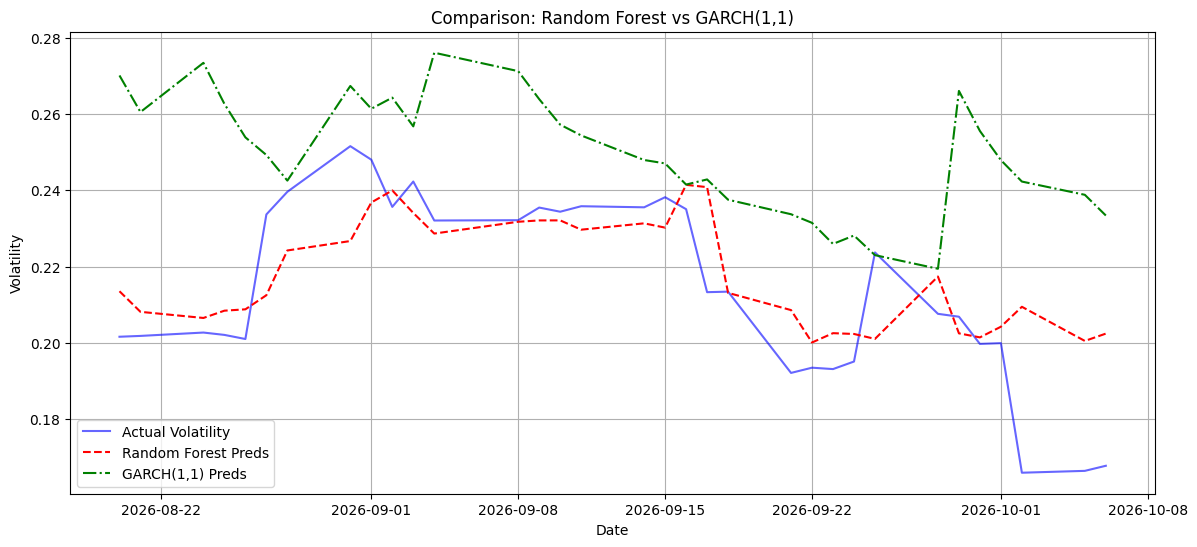

In [23]:
plt.figure(figsize=(14, 6))
plt.plot(y_test.index, y_test.values, label='Actual Volatility', color='blue', alpha=0.6)
plt.plot(y_test.index, predictions, label='Random Forest Preds', color='red', linestyle='--')
plt.plot(y_test.index, garch_preds, label='GARCH(1,1) Preds', color='green', linestyle='-.')
plt.title('Comparison: Random Forest vs GARCH(1,1)')
plt.xlabel('Date')
plt.ylabel('Volatility')
plt.legend()
plt.grid(True)
plt.show()

### 5. ตัวอย่างการคาดการณ์จริงล่วงหน้า 1 วันถัดไป (t+1 Out-of-Sample Prediction)

In [24]:
# 1. เลือกข้อมูลวันล่าสุด (Latest Available Date) ใน Dataset
latest_data = featured_data.iloc[-1:]
latest_date_str = latest_data.index[0].strftime('%Y-%m-%d')

# 2. เตรียมคุณลักษณะ (Features) สำหรับ Random Forest
X_latest = latest_data[features]

# ทำนายผลความผันผวนของวันถัดไป (t+1)
rf_next_day_pred = model.predict(X_latest)[0]

# 3. เตรียมข้อมูลสำหรับ GARCH(1,1)
# GARCH จะฟิตด้วยข้อมูล Return ทั้งหมดที่ผ่านมาจนถึงข้อมูลล่าสุดเพื่อพยากรณ์ไปข้างหน้า 1 คาบ
garch_final_model = arch_model(model_data['Log_Return'] * 100, vol='Garch', p=1, q=1, dist='normal')
garch_final_fitted = garch_final_model.fit(disp='off')
garch_forecast = garch_final_fitted.forecast(horizon=1)
garch_next_day_pred = np.sqrt(garch_forecast.variance.iloc[-1].values[0]) / 100 * np.sqrt(252)

# ป้องกันปัญหา MultiIndex สำหรับการพิมพ์ค่า Scalar
latest_close_val = latest_data['Close'].values[0]
if isinstance(latest_close_val, np.ndarray):
    latest_close_val = latest_close_val[0]

latest_vol_val = latest_data['Historical_Vol'].values[0]
if isinstance(latest_vol_val, np.ndarray):
    latest_vol_val = latest_vol_val[0]

print(f"ข้อมูลล่าสุด ณ วันที่: {latest_date_str}")
print(f"ราคาปิดล่าสุด (Close Price): {latest_close_val:.2f}")
print(f"ความผันผวนปัจจุบัน (Historical Volatility): {latest_vol_val:.4f}")
print("-" * 50)
print(f"[ทำนาย] ความผันผวนใน 1 วันทำการถัดไป โดย Random Forest : {rf_next_day_pred:.4f}")
print(f"[ทำนาย] ความผันผวนใน 1 วันทำการถัดไป โดย GARCH(1,1)    : {garch_next_day_pred:.4f}")

ข้อมูลล่าสุด ณ วันที่: 2026-10-07
ราคาปิดล่าสุด (Close Price): 4140.70
ความผันผวนปัจจุบัน (Historical Volatility): 0.1678
--------------------------------------------------
[ทำนาย] ความผันผวนใน 1 วันทำการถัดไป โดย Random Forest : 0.2014
[ทำนาย] ความผันผวนใน 1 วันทำการถัดไป โดย GARCH(1,1)    : 0.2309


In [25]:
import math

# คำนวณ Expected Move 1 วัน (รายวัน)
# สูตร: Price * Volatility * sqrt(1/252)
sqrt_one_day = math.sqrt(1 / 252)

# คำนวณกรอบการเคลื่อนไหวจากทั้งสองแบบจำลอง
rf_expected_move_pct = rf_next_day_pred * sqrt_one_day
rf_expected_move_usd = latest_close_val * rf_expected_move_pct

garch_expected_move_pct = garch_next_day_pred * sqrt_one_day
garch_expected_move_usd = latest_close_val * garch_expected_move_pct

print(f"=== การแปลง Volatility เป็น Expected Move สำหรับ 1 วันทำการถัดไป ===")
print(f"ราคาปิดทองคำล่าสุด: ${latest_close_val:.2f} USD\n")

print(f"1. [Random Forest] คาดการณ์ความผันผวน: {rf_next_day_pred*100:.2f}%")
print(f"   - Expected Move ( % ): ±{rf_expected_move_pct*100:.4f}%")
print(f"   - Expected Move (USD): ±${rf_expected_move_usd:.2f} USD")
print(f"   - กรอบราคาที่คาดหวัง (68% Confidence): ${latest_close_val - rf_expected_move_usd:.2f} ถึง ${latest_close_val + rf_expected_move_usd:.2f}\n")

print(f"2. [GARCH(1,1)] คาดการณ์ความผันผวน: {garch_next_day_pred*100:.2f}%")
print(f"   - Expected Move ( % ): ±{garch_expected_move_pct*100:.4f}%")
print(f"   - Expected Move (USD): ±${garch_expected_move_usd:.2f} USD")
print(f"   - กรอบราคาที่คาดหวัง (68% Confidence): ${latest_close_val - garch_expected_move_usd:.2f} ถึง ${latest_close_val + garch_expected_move_usd:.2f}")

=== การแปลง Volatility เป็น Expected Move สำหรับ 1 วันทำการถัดไป ===
ราคาปิดทองคำล่าสุด: $4140.70 USD

1. [Random Forest] คาดการณ์ความผันผวน: 20.14%
   - Expected Move ( % ): ±1.2686%
   - Expected Move (USD): ±$52.53 USD
   - กรอบราคาที่คาดหวัง (68% Confidence): $4088.17 ถึง $4193.23

2. [GARCH(1,1)] คาดการณ์ความผันผวน: 23.09%
   - Expected Move ( % ): ±1.4544%
   - Expected Move (USD): ±$60.22 USD
   - กรอบราคาที่คาดหวัง (68% Confidence): $4080.48 ถึง $4200.92


### บทสรุปการวิเคราะห์และการคาดการณ์ความผันผวน (Volatility Summary)

จากการดำเนินโครงการวิเคราะห์และสร้างแบบจำลองคาดการณ์ความผันผวนของราคาทองคำ (**Gold Futures - `GC=F`**) ในช่วงปี 2026 สามารถสรุปประเด็นสำคัญได้ดังนี้ครับ:

---

#### 1. การเตรียมข้อมูลและสร้างคุณลักษณะ (Data Pipeline & Feature Engineering)
* **ข้อมูลตั้งต้น**: ใช้ราคาทองคำรายวัน (`GC=F`) ตั้งแต่ `2026-01-01` ถึง `2026-10-08`
* **การคำนวณ Volatility**:
  * **Historical Volatility (21 วัน)**: คำนวณจาก Standard Deviation ของ Log Returns ปรับเป็นรายปี (Annualized)
  * **Parkinson Volatility (21 วัน)**: คำนวณโดยใช้ส่วนต่างของราคา High และ Low ซึ่งช่วยสะท้อนความผันผวนระหว่างวัน (Intraday Volatility) ได้ดีกว่าการใช้ราคาปิดเพียงอย่างเดียว

---

#### 2. การเปรียบเทียบประสิทธิภาพแบบจำลอง (Model Comparison)
เมื่อทำการทดสอบเพื่อทำนายความผันผวนของวันถัดไป ($t+1$) บน Test Set (สัดส่วนข้อมูลทดสอบ 20% ล่าสุด) ได้ผลลัพธ์ดังนี้:

| แบบจำลอง (Model) | RMSE | $R^2$ Score |
| :--- | :---: | :---: |
| **Random Forest Regressor (ML)** | **0.0157** | **0.5515** |
| **GARCH(1,1) (Statistical)** | **0.0419** | **-2.2010** |

* **วิเคราะห์ผลลัพธ์**:
  * **Random Forest** สามารถจับรูปแบบและทำนายความผันผวนได้ดีกว่าอย่างชัดเจน (มีค่า RMSE ต่ำกว่า และ $R^2$ เป็นบวกถึง 55.15%)
  * **GARCH(1,1)** มีประสิทธิภาพต่ำลงบนชุดข้อมูลทดสอบนี้ ($R^2$ เป็นลบ) เนื่องจากข้อจำกัดของ GARCH ที่มักลู่เข้าหาค่าเฉลี่ยระยะยาว (Mean Reversion) และอาจไม่ตอบสนองต่อการเปลี่ยนแปลงโครงสร้างความผันผวนอย่างรวดเร็วในกรอบเวลาสั้นได้ดีเท่ากับโมเดล Machine Learning ที่มี Feature หลากหลาย

---

#### 3. ผลการพยากรณ์จริงรายวันและการคำนวณ Expected Move (สำหรับวันถัดไป)
อ้างอิงข้อมูลล่าสุด ณ วันที่ **2026-10-07** ที่ราคาปิด **$4,140.70 USD** และความผันผวนปัจจุบันอยู่ที่ **16.78%** ผลลัพธ์คาดการณ์กรอบราคาใน 1 วันทำการถัดไป ($t+1$) ภายใต้ระดับความเชื่อมั่น 68% (1 Standard Deviation) มีดังนี้:

* **คาดการณ์โดย Random Forest (Volatility: 20.14%)**
  * **Expected Move ( % )**: $\pm1.27\%$
  * **Expected Move (USD)**: $\pm\$52.53$ USD
  * **กรอบราคาคาดหวัง**: **$4,088.17 ถึง $4,193.23**

* **คาดการณ์โดย GARCH(1,1) (Volatility: 23.09%)**
  * **Expected Move ( % )**: $\pm1.45\%$
  * **Expected Move (USD)**: $\pm\$60.22$ USD
  * **กรอบราคาคาดหวัง**: **$4,080.48 ถึง $4,200.92**

---

#### 4. ข้อเสนอแนะเชิงกลยุทธ์สำหรับการนำไปใช้ (Actionable Insights)
1. **การบริหารความเสี่ยง (Risk Management)**: กรอบ Expected Move ที่คำนวณได้สามารถนำไปใช้ตั้งค่าระดับ Stop Loss ที่ปลอดภัย โดยอยู่นอกกรอบความเคลื่อนไหวปกติทางสถิติ ($> 1 \text{ SD}$)
2. **การเทรด Options**: หากนักลงทุนคาดว่าตลาดจะเคลื่อนไหวในกรอบแคบ สามารถใช้กรอบจาก Random Forest หรือ GARCH เป็นแนวทางในการวางกลยุทธ์จำพวก Short Straddle หรือ Iron Condor ได้
3. **การประเมิน Leverage**: ความผันผวนที่พุ่งขึ้นจาก ~16.78% เป็นระดับคาดการณ์ที่ 20% - 23% บ่งชี้ว่าตลาดกำลังเข้าสู่ช่วงความไม่แน่นอนที่สูงขึ้น นักเทรดฝั่ง Futures ควรลดขนาดสัญญา (Position Sizing) เพื่อรักษาระดับ Margin ให้ปลอดภัย